In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_raw, add_target, get_X_y
from src.models import get_models
from src.evaluate import make_estimator, score_predictions
from src.config import SCENARIOS, FIGURES_DIR

por = add_target(load_raw("por"))   # training data
mat = add_target(load_raw("mat"))   # unseen subject, test only

print("Portuguese:", por.shape, "| Math:", mat.shape)
print("Same columns in the same order?", list(por.columns) == list(mat.columns))

Portuguese: (649, 34) | Math: (395, 34)
Same columns in the same order? True


In [2]:
comparison = pd.DataFrame({
    "Portuguese": [por["fail"].mean(), por["G1"].mean(), por["G3"].mean(), (por["G3"] == 0).mean()],
    "Math":       [mat["fail"].mean(), mat["G1"].mean(), mat["G3"].mean(), (mat["G3"] == 0).mean()],
}, index=["fail rate", "mean G1", "mean G3", "share with G3 = 0"])

comparison.round(3)

,Portuguese,Math
fail rate,0.154,0.329
mean G1,11.399,10.909
mean G3,11.906,10.415
share with G3 = 0,0.023,0.096


In [3]:
MODEL = "Logistic Regression"
cv_results = pd.read_csv(ROOT / "reports" / "cv_results.csv")   # saved in Stage 4
metrics = ["fail_recall", "fail_precision", "fail_f1", "roc_auc", "pr_auc"]

rows = []
for scenario in SCENARIOS:
    X_por, y_por = get_X_y(por, scenario)
    X_mat, y_mat = get_X_y(mat, scenario)

    # Train ONCE on all Portuguese students (with the same light tuning as before)
    model, scale, grid = get_models()[MODEL]
    final = make_estimator(model, scale, grid, X_por).fit(X_por, y_por).best_estimator_

    # Test on Math students the model never saw
    test = score_predictions(y_mat, final.predict_proba(X_mat)[:, 1])

    # Portuguese CV result for the same model + scenario
    cv_row = cv_results[(cv_results["scenario"] == scenario) &
                        (cv_results["model"] == MODEL)].iloc[0]

    for m in metrics:
        rows.append({"scenario": scenario, "metric": m,
                     "portuguese_cv": cv_row[m], "math_test": test[m]})

gen = pd.DataFrame(rows)
gen["change"] = gen["math_test"] - gen["portuguese_cv"]
gen.to_csv(ROOT / "reports" / "generalization_results.csv", index=False)
gen.round(3)

,scenario,metric,portuguese_cv,math_test,change
0,a_no_grades,fail_recall,0.660,0.415,-0.245
1,a_no_grades,fail_precision,0.350,0.600,0.250
2,a_no_grades,fail_f1,0.456,0.491,0.035
3,a_no_grades,roc_auc,0.791,0.640,-0.151
4,a_no_grades,pr_auc,0.435,0.543,0.108
5,b_G1_only,fail_recall,0.860,0.731,-0.129
6,b_G1_only,fail_precision,0.513,0.720,0.206
7,b_G1_only,fail_f1,0.641,0.725,0.084
8,b_G1_only,roc_auc,0.931,0.908,-0.023
9,b_G1_only,pr_auc,0.693,0.820,0.127


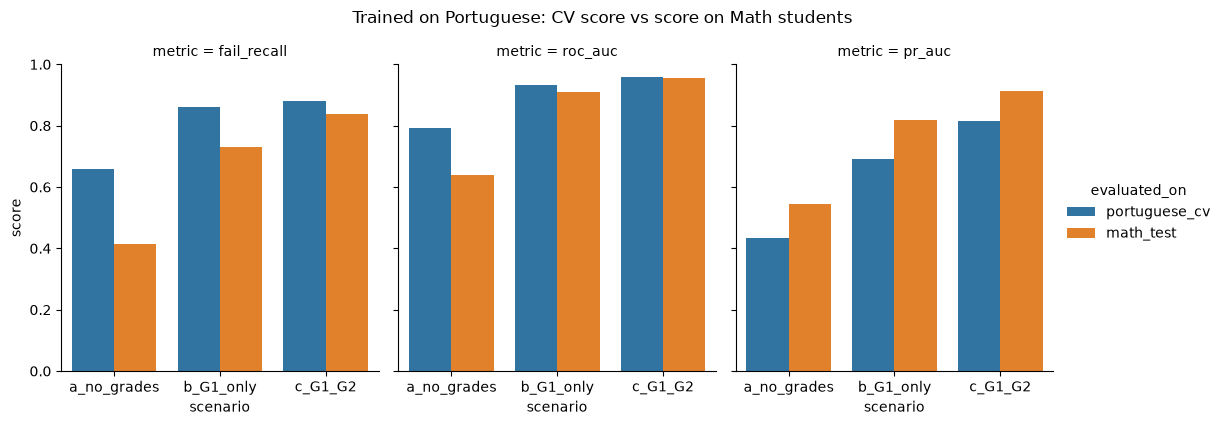

In [4]:
plot_df = gen[gen["metric"].isin(["fail_recall", "roc_auc", "pr_auc"])].melt(
    id_vars=["scenario", "metric"], value_vars=["portuguese_cv", "math_test"],
    var_name="evaluated_on", value_name="score")

g = sns.catplot(data=plot_df, x="scenario", y="score", hue="evaluated_on",
                col="metric", kind="bar", height=4, aspect=0.9)
g.set(ylim=(0, 1))
g.figure.suptitle("Trained on Portuguese: CV score vs score on Math students", y=1.05)
g.savefig(FIGURES_DIR / "13_generalization.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
print(f"PR-AUC of a no-skill model on Portuguese: {por['fail'].mean():.3f}")
print(f"PR-AUC of a no-skill model on Math:       {mat['fail'].mean():.3f}")
print("→ Judge PR-AUC against these baselines, not against each other.")

PR-AUC of a no-skill model on Portuguese: 0.154
PR-AUC of a no-skill model on Math:       0.329
→ Judge PR-AUC against these baselines, not against each other.


In [ ]:
'''## Generalization conclusions (Portuguese → Math)

- Math fail rate: XX% (vs ~15% in Portuguese). The base rate shifts, which by
  itself changes precision, recall and PR-AUC.
- ROC-AUC (ranking quality, not affected by base rate): scenario (b)
  0.93 (Portuguese CV) → 0.XX (Math).
- [Describe: did the model hold up? Which scenario dropped most?]
- Caveat: according to the dataset documentation, ~382 students appear in both
  files, so this tests a new subject more than new students.
- Recommendation: before using the model for a new subject, re-check the
  decision threshold (or retrain) on that subject's data.'''